# Evaluación de mi modelo de predicción del Mundial 2026

**Pregunta:** ¿qué tan bien predijo mi modelo y le ganó a lo obvio (el ranking FIFA)?

Dos evaluaciones separadas:
1. **Las 12 predicciones reales** que hice antes de cada partido durante el torneo (v0, v1, v2).
2. **El modelo v2 reconstruido** con datos públicos previos al 11 de junio de 2026, aplicado a los 104 partidos y a una simulación Monte Carlo de 10,000 torneos.

Rivales: *solo ranking FIFA*, *solo Elo* y *adivinar 1/3*.

**Reglas de las métricas**
- *Acierto*: en grupos, resultado a 90′ (L/E/V); en eliminación, **quién avanzó** (la final cuenta como acierto aunque iba 0-0 a los 90′).
- *Brier y log-loss*: siempre el **resultado a 90′** (L/E/V), en las dos fases.

In [1]:
import sys, json, pandas as pd
sys.path.insert(0, 'src')
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
from IPython.display import Image, display

## 1. Datos
104 partidos (resultado a 90′, resultado final, penales, quién avanzó), verificados contra la tabla de posiciones de los 12 grupos y contra la base histórica de partidos internacionales de martj42.

In [2]:
partidos = pd.read_csv('data/processed/mundial2026_partidos.csv')
print(partidos.shape); partidos.groupby('fase', sort=False).size()

(104, 25)


fase
Grupos           72
Dieciseisavos    16
Octavos           8
Cuartos           4
Semifinal         2
Tercer lugar      1
Final             1
dtype: int64

In [3]:
partidos[partidos.pred_version.notna()][['match_id','fase','local','visitante','goles_local_90','goles_visitante_90','avanza',
  'pred_version','pred_v0','pred_emitida','puntaje_local_reportado','puntaje_visitante_reportado',
  'puntaje_local_recalculado','puntaje_visitante_recalculado','acierto_emitida']]

,match_id,fase,local,visitante,goles_local_90,goles_visitante_90,avanza,pred_version,pred_v0,pred_emitida,puntaje_local_reportado,puntaje_visitante_reportado,puntaje_local_recalculado,puntaje_visitante_recalculado,acierto_emitida
27,28,Grupos,México,Corea del Sur,1,0,NaN,v0,NaN,México o empate,NaN,NaN,NaN,NaN,sí
54,55,Grupos,Curazao,Costa de Marfil,0,2,NaN,v1,Visitante,Visitante,5.00,6.50,NaN,NaN,sí
55,56,Grupos,Ecuador,Alemania,2,1,NaN,v1,Visitante,Visitante,5.50,8.20,NaN,8.30,no
56,57,Grupos,Japón,Suecia,1,1,NaN,v1,Empate,Local,7.30,6.80,7.45,NaN,no
57,58,Grupos,Túnez,Países Bajos,1,3,NaN,v1,Visitante,Visitante,4.00,7.10,NaN,NaN,sí
58,59,Grupos,Turquía,EE.UU.,3,2,NaN,v1,Visitante,Visitante,5.00,7.20,NaN,7.25,no
59,60,Grupos,Paraguay,Australia,0,0,NaN,v1,Local,Empate,6.20,6.20,6.10,6.20,sí
78,79,Dieciseisavos,México,Ecuador,2,0,México,v1,NaN,México,7.65,5.95,7.35,5.85,sí
91,92,Octavos,México,Inglaterra,2,3,Inglaterra,v1,NaN,México,7.65,7.55,7.35,7.55,no
100,101,Semifinal,Francia,España,0,2,España,v1,NaN,España,9.35,9.30,9.03,9.25,sí


## 2. Las 12 predicciones reales

Se evalúa **lo que se predijo en su momento** (puntajes reportados), aunque tres totales tenían errores de cuenta:

| Partido | Predicción emitida | Con la fórmula bien aplicada | Real |
|---|---|---|---|
| Paraguay–Australia | Empate | Australia | 0-0 |
| México–Inglaterra | México | Inglaterra | Inglaterra |
| Francia–España | España (desempate a criterio) | España | España |

Uno ayudó y otro perjudicó: el saldo de los errores es cero.

In [4]:
import evaluacion
R = json.load(open('resultados/resultados.json', encoding='utf-8'))
doce = pd.DataFrame(R['doce'])
print('Aciertos:', (doce.acierto == 'sí').sum(), 'de', len(doce))
doce[['partido','version','pred','real_90','avanza','acierto','p_chat','brier_chat','brier_v2r','brier_fifa']].round(3)

Aciertos: 8 de 12


,partido,version,pred,real_90,avanza,acierto,p_chat,brier_chat,brier_v2r,brier_fifa
0,México–Corea del Sur,v0,México o empate,1-0,,sí,NaN,NaN,0.222,0.432
1,Curazao–Costa de Marfil,v1,Visitante,0-2,,sí,"[0.083, 0.152, 0.764]",0.086,0.058,0.073
2,Ecuador–Alemania,v1,Visitante,2-1,,no,"[0.011, 0.039, 0.95]",1.882,1.128,0.835
3,Japón–Suecia,v1,Local,1-1,,no,"[0.504, 0.249, 0.248]",0.879,1.303,0.922
4,Túnez–Países Bajos,v1,Visitante,1-3,,sí,"[0.005, 0.019, 0.976]",0.001,0.193,0.145
5,Turquía–EE.UU.,v1,Visitante,3-2,,no,"[0.029, 0.077, 0.894]",1.748,0.468,0.691
6,Paraguay–Australia,v1,Empate,0-0,,sí,"[0.368, 0.264, 0.368]",0.813,0.860,0.868
7,México–Ecuador,v1,México,2-0,México,sí,"[0.807, 0.129, 0.063]",0.058,0.374,0.461
8,México–Inglaterra,v1,México,2-3,Inglaterra,no,"[0.394, 0.263, 0.342]",0.657,0.355,0.447
9,Francia–España,v1,España,0-2,España,sí,"[0.381, 0.264, 0.355]",0.631,0.782,0.588


In [5]:
d = doce.dropna(subset=['brier_chat'])
pd.Series({'Mis predicciones (v1/v2)': d.brier_chat.mean(), 'v2 reconstruido': d.brier_v2r.mean(),
           'Solo ranking FIFA': d.brier_fifa.mean(), 'Adivinar 1/3': 2/3}, name=f'Brier promedio en {len(d)} partidos').round(3)

Mis predicciones (v1/v2)    0.752
v2 reconstruido             0.649
Solo ranking FIFA           0.582
Adivinar 1/3                0.667
Name: Brier promedio en 11 partidos, dtype: float64

**Ojo:** mi modelo nunca dio probabilidades. Para calcular un Brier hay que convertir los puntajes con una regla (aquí, calibrada con la propia tabla del chat del 25-jun). El resultado **depende de esa regla** tanto como del modelo:

In [6]:
pd.Series(R['sensibilidad_12'], name='Brier de mis 11 predicciones con puntaje, según el supuesto de conversión').rename(lambda r: f'favorito espera {float(r):.0f}x goles').round(3)

favorito espera 3x goles    0.700
favorito espera 4x goles    0.723
favorito espera 6x goles    0.752
favorito espera 9x goles    0.773
Name: Brier de mis 11 predicciones con puntaje, según el supuesto de conversión, dtype: float64

En todos los supuestos el Brier queda igual o peor que adivinar 1/3 (0.667), pero esto mide la conversión tanto como el modelo. **El dato limpio es 8 de 12 aciertos.**

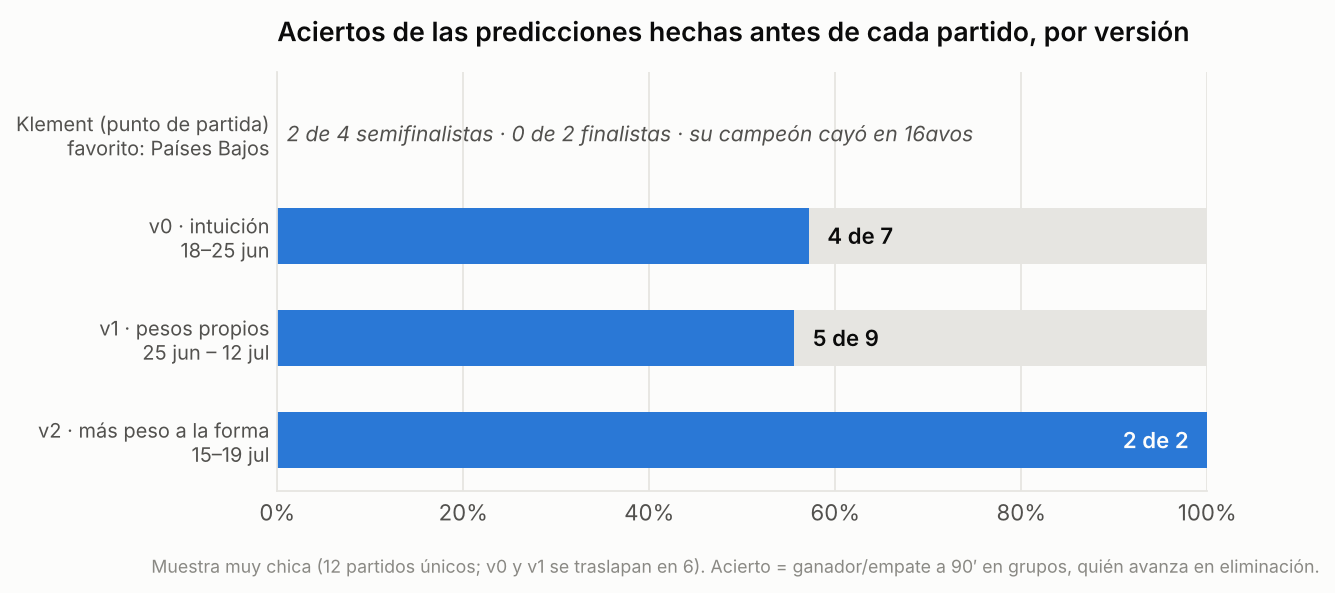

In [7]:
display(Image('graficas/1_evolucion_modelo.png'))

## 3. Modelo v2 reconstruido (datos previos al 11-jun-2026)

Misma fórmula que la v2: `0.20·FIFA + 0.20·Top5 + 0.10·Edad + 0.10·Continuidad + 0.30·Forma + 0.10·Clima`, cada variable medida con datos objetivos:

In [8]:
import modelo
for k, v in modelo.REGLAS.items(): print(f'{k:6s} {v}')
pd.read_csv('resultados/puntajes_48_equipos.csv').head(16)

fifa   FIFA = 10 − 9·(rank−1)/84  (rank 1 → 10, rank 85 → 1)
top5   Top5 = 1 + 9·(% de la plantilla en 1a división de ENG/ESP/ITA/GER/FRA 2025-26)
edad   Edad = 10 − 3·|edad_promedio − 27|  (pico 25–29; 27 = centro), mínimo 1
cont   Continuidad = 1 + 9·min(meses del técnico al 11-jun-2026, 96)/96
forma  Forma = cambio de Elo entre 11-jun-2025 y 11-jun-2026, reescalado min–max a 1–10 entre los 48
clima  Clima (por partido) = 10 − 0.3·|T_sede − T_casa| − penalización de altitud; estadios climatizados T_sede = 22 °C


,equipo,grupo,FIFA,Top5,Edad,Continuidad,Forma,puntaje_sin_clima(clima=7),elo_pre,delta_elo_12m
0,Francia,I,9.79,9.31,8.74,10.00,5.37,8.00,2126,10
1,Inglaterra,L,9.68,9.66,8.86,2.59,6.98,7.81,2091,43
2,Suiza,B,8.07,8.96,7.57,6.44,7.09,7.64,1957,46
3,Bélgica,G,9.14,7.92,9.64,2.59,7.39,7.55,1958,52
4,España,H,9.89,10.00,7.57,4.94,4.88,7.39,2220,0
5,Alemania,E,9.04,9.66,8.38,4.09,5.67,7.39,2005,16
6,Japón,F,8.18,5.16,9.43,9.91,6.43,7.23,1994,32
7,Noruega,I,6.79,6.89,8.05,7.19,7.50,7.21,1972,54
8,Marruecos,C,9.36,6.19,6.76,1.28,8.53,7.17,1986,75
9,Argentina,J,10.00,7.92,5.14,9.81,4.21,7.04,2191,-14


**De puntaje a probabilidades (regla fija, no calibrada con 2026):** goles esperados `λ = 1.30·exp(±β·d)` (Poisson), con β elegido para que en el desequilibrio del percentil 95 el favorito espere 6 veces más goles. Se aplica la misma regla a todos los modelos.

In [9]:
res = pd.DataFrame(R['resumen_104']).T[['brier','logloss','aciertos']]
res['brier'] = res.brier.round(3); res['logloss'] = res.logloss.round(3); res

,brier,logloss,aciertos
v2 reconstruido,0.534,0.909,60.0
v2 · forma = nivel Elo (post hoc),0.514,0.877,65.0
Solo ranking FIFA,0.547,0.923,64.0
Solo Elo,0.534,0.917,64.0
Uniforme (1/3),0.667,1.099,0.0


In [10]:
print('Diferencia de Brier (v2 reconstruido − rival), media e IC 95% por bootstrap:')
for k, (m, lo, hi) in R['bootstrap'].items(): print(f'  vs {k:20s} {m:+.3f}  [{lo:+.3f}, {hi:+.3f}]')
print('\nSensibilidad al supuesto de 6x (Brier):'); pd.DataFrame(R['sensibilidad']).round(3)

Diferencia de Brier (v2 reconstruido − rival), media e IC 95% por bootstrap:
  vs Solo ranking FIFA    -0.013  [-0.065, +0.039]
  vs Solo Elo             +0.000  [-0.059, +0.058]
  vs Uniforme (1/3)       -0.133  [-0.212, -0.053]

Sensibilidad al supuesto de 6x (Brier):


,4.0,6.0,9.0
v2 reconstruido,0.541,0.534,0.535
v2 · forma = nivel Elo (post hoc),0.522,0.514,0.513
Solo ranking FIFA,0.549,0.547,0.551
Solo Elo,0.538,0.534,0.535
Uniforme (1/3),0.667,0.667,0.667


### Análisis de sensibilidad post hoc: forma = nivel de Elo
La versión principal mide la forma como **cambio** de Elo en 12 meses (decisión de la reconstrucción, tomada antes de evaluar). Después de ver los resultados se probó medirla como **nivel** de Elo. Se reporta como sensibilidad, **no** como el modelo: se eligió viendo los datos y además usa el propio Elo como 30% del puntaje.

In [11]:
print('Diferencia de Brier (variante post hoc − rival), media e IC 95%:')
for k, (m, lo, hi) in R['bootstrap_posthoc'].items(): print(f'  vs {k:20s} {m:+.3f}  [{lo:+.3f}, {hi:+.3f}]')

Diferencia de Brier (variante post hoc − rival), media e IC 95%:
  vs Solo Elo             -0.020  [-0.051, +0.011]
  vs Solo ranking FIFA    -0.033  [-0.066, -0.002]
  vs v2 reconstruido      -0.020  [-0.056, +0.016]


Mejora el puntaje (0.534 → 0.514), pero **no le gana con claridad al Elo**: el intervalo incluye el cero.

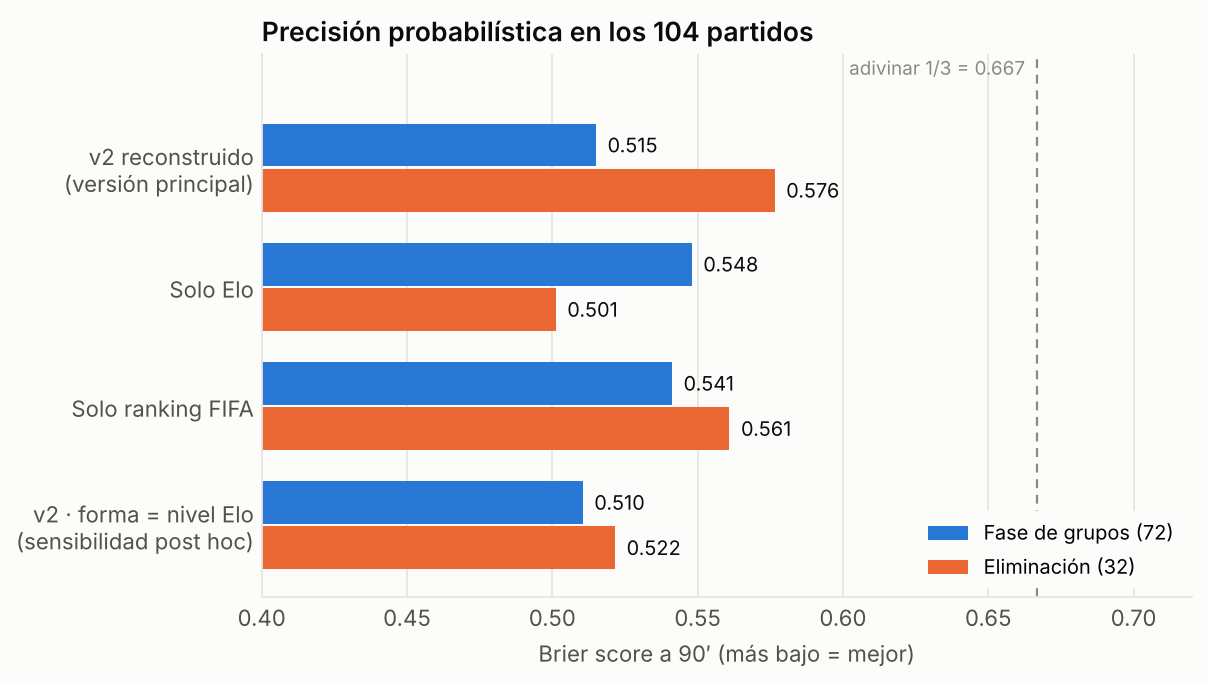

In [12]:
display(Image('graficas/2_brier_por_fase.png'))

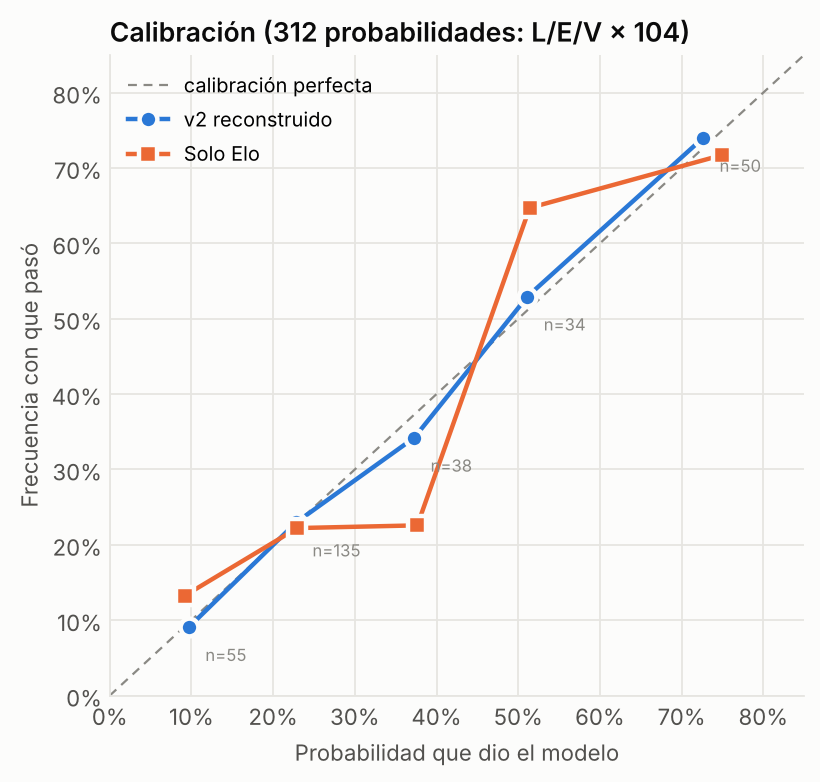

In [13]:
display(Image('graficas/5_calibracion.png'))

## 4. Simulación Monte Carlo (10,000 torneos)
Calendario y sedes reales; empates en eliminación → tiempo extra (λ/3) → penales 50/50.

In [14]:
mc = R['montecarlo']
tabla = pd.DataFrame({k: {e: v[6] for e, v in sim.items()} for k, sim in mc.items()})
tabla.sort_values('v2 reconstruido', ascending=False).head(10).mul(100).round(1)

,v2 reconstruido,v2 · forma = nivel Elo (post hoc),Solo ranking FIFA,Solo Elo
Francia,14.6,20.2,8.3,10.9
Inglaterra,11.4,8.4,8.1,7.1
Suiza,10.2,3.1,2.0,1.0
Bélgica,8.7,2.5,5.0,0.8
España,6.6,17.6,8.9,28.6
Japón,5.8,2.9,1.7,1.2
Alemania,5.4,4.5,4.8,2.0
Argentina,4.7,17.0,9.0,20.8
Marruecos,4.7,1.0,5.9,1.2
Costa de Marfil,4.1,0.1,0.3,0.0


In [15]:
print('Probabilidad de que España fuera campeona:', {k: round(mc[k]['España'][6]*100, 1) for k in mc})
print('Log-verosimilitud media de la fase real alcanzada (más alto = mejor):', {k: round(v, 3) for k, v in R['mc_loglik'].items()})

Probabilidad de que España fuera campeona: {'v2 reconstruido': 6.6, 'v2 · forma = nivel Elo (post hoc)': 17.6, 'Solo ranking FIFA': 8.9, 'Solo Elo': 28.6}
Log-verosimilitud media de la fase real alcanzada (más alto = mejor): {'v2 reconstruido': -1.197, 'v2 · forma = nivel Elo (post hoc)': -1.147, 'Solo ranking FIFA': -1.315, 'Solo Elo': -1.228}


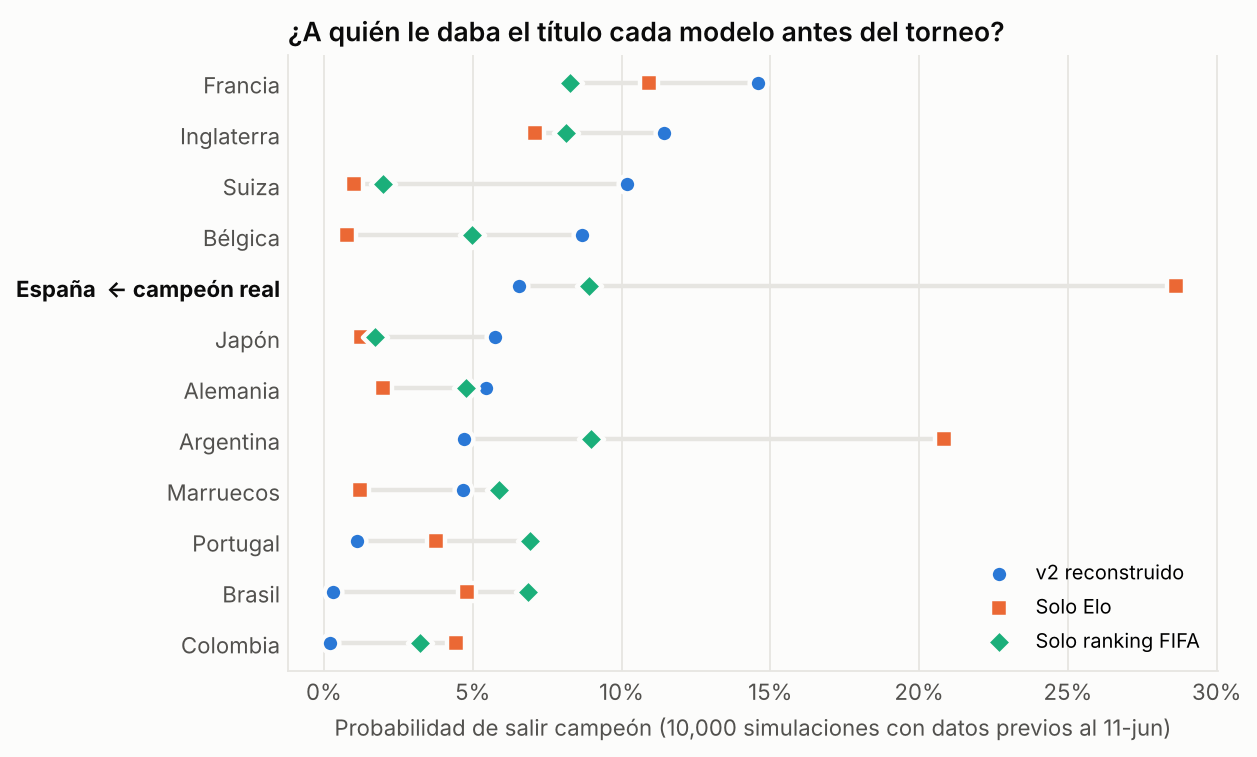

In [16]:
display(Image('graficas/3_probabilidad_campeon.png'))

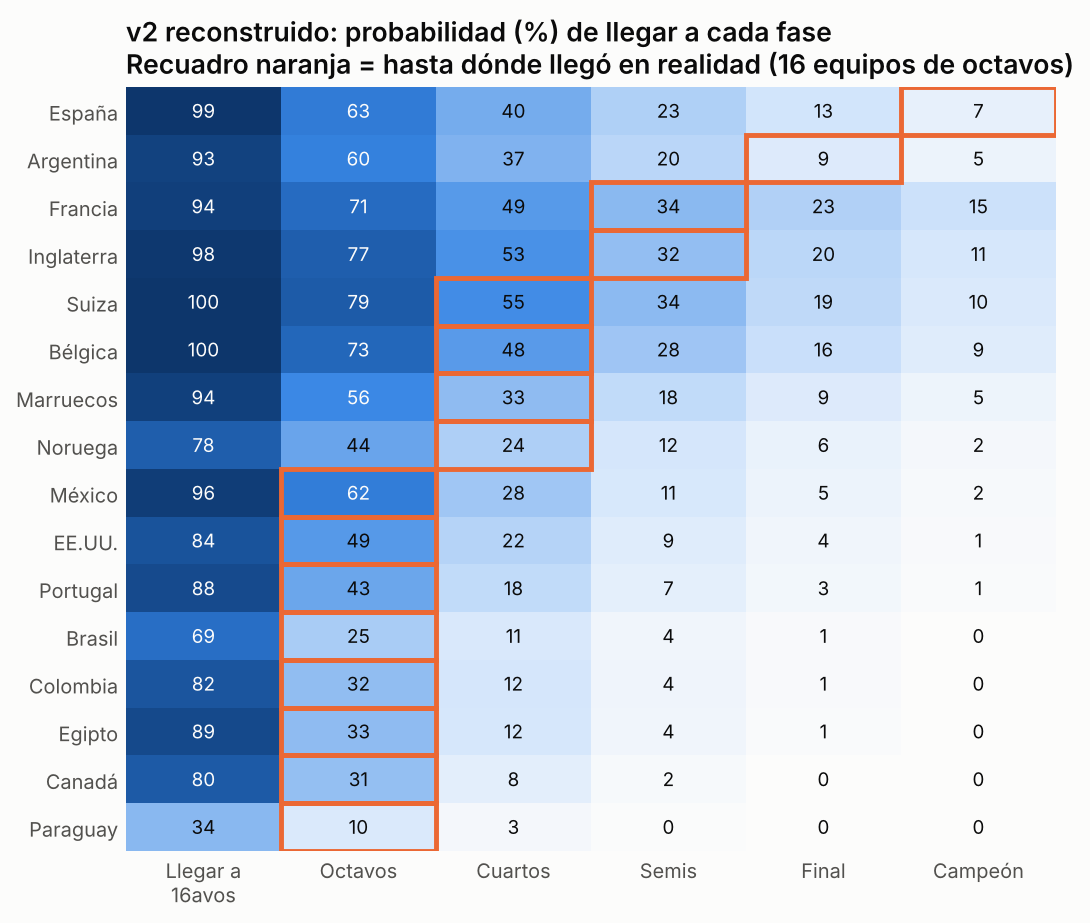

In [17]:
display(Image('graficas/4_fases_vs_realidad.png'))

## 5. Conclusiones
- Mis 12 predicciones: **8 aciertos** (dato limpio). El Brier depende de cómo se conviertan los puntajes a probabilidades.
- Klement (punto de partida): de lo que publicó, acertó 2 de 4 semifinalistas (España, Inglaterra), 0 de 2 finalistas y su campeón (Países Bajos) cayó en dieciseisavos.
- El v2 reconstruido **no le gana de forma clara al ranking FIFA ni al Elo** en los 104 partidos: la diferencia cabe dentro del ruido.
- Fue mejor en **grupos** y peor en **eliminación**; está bien calibrado.
- En la simulación, el v2 reconstruido favorecía a Francia (15%) y a España solo con 7%; el Elo puro le daba a España 29%. Eso se debe sobre todo a **cómo se reconstruyó la forma** (cambio de Elo), no necesariamente a tu v2 original: con forma = nivel de Elo (post hoc), España sube a 18%.
- Aun así, el v2 describió mejor hasta dónde llegó cada equipo (Suiza, Bélgica, Noruega, Marruecos).

Limitaciones completas en el README.